<a href="https://colab.research.google.com/github/AgentForgeWorkshop/Tutorials/blob/main/Tutorial1_frameworks/01a_what_is_an_agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 1A: What is an agent?

**AgentForge Workshop · Tutorial 1, notebook A of 2 · about 22 minutes**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AgentForgeWorkshop/Tutorials/blob/main/Tutorial1_frameworks/01a_what_is_an_agent.ipynb)

In the slides, an agent was **an LLM running in a loop, plus a harness that builds the context
and runs the tools.** In this notebook you will see that idea in code:

> Send the conversation **plus a list of tool descriptions** to the LLM.
> If it replies asking to call a tool, **run that Python function**, add the result to the
> conversation, and call the LLM again. Stop when it replies with plain text.

You will write that loop yourself in about twenty lines, add **guardrails** to it, and then
see the same agent in **LangChain** (built on **LangGraph**). Every framework is "the loop,
plus conveniences".

| Step | What | Min |
|---|---|---|
| 0 | Setup | 3 |
| 1 | A bare LLM fails at a literature question | 2 |
| 2 | A tool is just a Python function | 3 |
| 3 | **The loop**, written by hand | 6 |
| 4 | Guardrails are code in the loop | 4 |
| 5 | The same agent in LangChain, and the LangGraph inside it | 4 |
| | *Take-home: the same agent in Pydantic AI and DeepAgents; exercises* | |

**Notebook B** then builds the same task as an LLM call, a workflow, an agentic workflow and
an agent, and compares them.

---
## Step 0: Setup

Run the next cell once. It takes about a minute. A warning about "pip dependency
google-colab" is expected and harmless.

In [1]:
%pip install -q "langchain==1.4.2" "langchain-google-genai==4.4.0" "langchain-openai==1.6.2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.7/163.7 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.6/81.6 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 9.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


### Your API key

1. Open <https://openrouter.ai/keys> and create a key (the workshop gives you credit).
2. In Colab, click the **🔑 key icon** in the left sidebar (Secrets).
3. Add a secret named exactly `OPENROUTER_API_KEY`, paste your key, and turn on
   **Notebook access**.

A key pasted into a cell gets saved into the notebook, and notebooks get shared. Treat an API
key like a password.

In [2]:
import getpass
import os

from langchain.chat_models import init_chat_model


def get_key(name: str) -> str:
    """Read an API key from Colab's Secrets panel, or ask for it if there is none."""
    try:
        from google.colab import userdata

        return userdata.get(name)
    except Exception:  # not in Colab, or that secret is not set
        return os.environ.get(name) or getpass.getpass(f"{name}: ")


PROVIDER = "openrouter"  # <-- "openrouter" or "google"

if PROVIDER == "openrouter":
    # Any id from https://openrouter.ai/models that supports tool calling ("Tools" filter).
    OPENROUTER_MODEL = "deepseek/deepseek-v4.1-flash"
    os.environ["OPENROUTER_API_KEY"] = get_key("OPENROUTER_API_KEY")
    MODEL_NAME = f"openai:{OPENROUTER_MODEL}"  # OpenRouter speaks the OpenAI API
    model = init_chat_model(
        MODEL_NAME,
        temperature=0,
        base_url="https://openrouter.ai/api/v1",
        api_key=os.environ["OPENROUTER_API_KEY"],
    )
    PAI_MODEL = f"openrouter:{OPENROUTER_MODEL}"  # the same model, spelled for Pydantic AI

elif PROVIDER == "google":
    os.environ["GOOGLE_API_KEY"] = get_key("GOOGLE_API_KEY")
    MODEL_NAME = "google_genai:gemini-3.5-flash"
    model = init_chat_model(MODEL_NAME, temperature=0)
    PAI_MODEL = "google:gemini-3.5-flash"

print("Model ready:", MODEL_NAME)
print(model.invoke("Reply with exactly: ready").text)

Model ready: openai:deepseek/deepseek-v4.1-flash
ready


---
## Step 1: Why a bare LLM is not enough

This is the "chatbot" from the slides: text in, text out. Pick a topic you care about and ask
it for this week's papers.

In [3]:
TOPIC = "machine learning interatomic potentials for catalysis"  # <-- change me

answer = model.invoke(
    f"List 5 papers on '{TOPIC}' that were posted to arXiv in the last two weeks. "
    "Give the title, the authors and the arXiv link for each."
)
print(answer.text)

I can’t reliably list 5 arXiv papers posted in the last two weeks (2026-04-25 to 2026-05-09) because I don’t have live arXiv/web access, and my training data does not cover that period. I don’t want to fabricate titles, authors, or links.

You can retrieve them directly with the arXiv API, for example:

```text
http://export.arxiv.org/api/query?search_query=all:%22machine%20learning%20interatomic%20potentials%22+AND+all:catalysis&start=0&max_results=50&sortBy=submittedDate&sortOrder=descending
```

Then filter the returned entries by `<published>` date between **2026-04-25** and **2026-05-09**. A broader query that may catch more relevant papers is:

```text
http://export.arxiv.org/api/query?search_query=(all:%22machine%20learning%20potential%22+OR+all:%22machine%20learning%20interatomic%20potential%22+OR+all:%22MLIP%22)+AND+all:catalysis&start=0&max_results=100&sortBy=submittedDate&sortOrder=descending
```

If you paste the API results or enable browsing, I can select the 5 most relev

You get one of two things, and both make the point:

* **A refusal.** "I have no live access, my training data ends in…". Often it also guesses
  today's date wrong, because it has no way to know it.
* **Confident, plausible, unverifiable output.** Titles that sound real and arXiv IDs that
  may point to a different paper. This is how fake references end up in bibliographies.

The model is not lying: it has no connection to arXiv, it is completing text. **The fix is to
give it a way to look things up.** That is all a tool is.

---
## Step 2: A tool is just a Python function

`search_arxiv` is an ordinary function: no framework, no base class. It calls the public arXiv
API (no key needed) and returns a **string**, because a string is what we can put into a
conversation with an LLM.

One detail matters: arXiv treats each search term as a single word, so
`all:machine learning interatomic potentials` silently searches for "machine" and returns
near-random papers. `build_arxiv_query` ANDs the words together instead. Every data API has a
quirk like this: **the tool has to be right before the agent can be.**

In [4]:
import re
import textwrap
import urllib.parse
import urllib.request
import xml.etree.ElementTree as ET

ARXIV_API = "https://export.arxiv.org/api/query"
ATOM = {"atom": "http://www.w3.org/2005/Atom"}

# Words that add nothing to a search and would only narrow the results for no reason.
STOPWORDS = {"a", "an", "and", "are", "as", "at", "based", "by", "for", "from", "in",
             "into", "is", "of", "on", "or", "the", "to", "use", "using", "via", "with"}


def build_arxiv_query(topic: str) -> str:
    """Translate a plain-English topic into arXiv's query language (AND of the words)."""
    words = re.findall(r"[A-Za-z0-9][\w'-]*", topic)
    terms = [w for w in words if w.lower() not in STOPWORDS]
    return " AND ".join(f"all:{w}" for w in terms) or f"all:{topic}"


def search_arxiv(query: str, max_results: int = 5) -> str:
    """Search arXiv for recent papers and return their titles, authors, links and abstracts.

    Args:
        query: Search terms, e.g. 'graph neural network catalyst screening'.
        max_results: How many papers to return (1-10).
    """
    search_query = build_arxiv_query(query)
    params = urllib.parse.urlencode(
        {
            "search_query": search_query,
            "start": 0,
            "max_results": min(max_results, 10),
            "sortBy": "submittedDate",
            "sortOrder": "descending",
        }
    )
    with urllib.request.urlopen(f"{ARXIV_API}?{params}", timeout=30) as response:
        feed = ET.fromstring(response.read())

    papers = []
    for entry in feed.findall("atom:entry", ATOM):
        title = " ".join(entry.findtext("atom:title", "", ATOM).split())
        abstract = " ".join(entry.findtext("atom:summary", "", ATOM).split())
        authors = [a.findtext("atom:name", "", ATOM) for a in entry.findall("atom:author", ATOM)]
        papers.append(
            f"Title: {title}\n"
            f"Authors: {', '.join(authors[:3])}{' et al.' if len(authors) > 3 else ''}\n"
            f"Published: {entry.findtext('atom:published', '', ATOM)[:10]}\n"
            f"Link: {entry.findtext('atom:id', '', ATOM)}\n"
            f"Abstract: {textwrap.shorten(abstract, 1000, placeholder=' ...')}"
        )

    if not papers:
        # Telling the agent what we actually sent lets it retry with fewer terms.
        return (
            f"No papers found for '{query}' (sent to arXiv as: {search_query}). "
            "Try fewer or broader search terms."
        )
    return "\n\n---\n\n".join(papers)

In [5]:
# No LLM involved: it is an ordinary function, so just call it.
print("arXiv sees:", build_arxiv_query(TOPIC), "\n")
print(search_arxiv(TOPIC, max_results=2))

arXiv sees: all:machine AND all:learning AND all:interatomic AND all:potentials AND all:catalysis 

Title: Can Universal Machine-Learning Interatomic Potentials Capture Small Polarons? A Geometry-Based Benchmark in Transition-Metal Oxides
Authors: Vladislav Korostelev, Pjotrs Žguns, Konstantin Klyukin
Published: 2026-10-12
Link: http://arxiv.org/abs/2610.17352v1
Abstract: Small polarons, formed when excess electrons become localized through lattice distortions, play a critical role in charge transport, catalysis, and degradation processes in transition-metal (TM) oxides. Whether universal machine-learning interatomic potentials (uMLIPs), which lack explicit electronic degrees of freedom, can describe them remains unclear. Here, we investigate H-induced electron localization across a range of TM oxides using a geometric descriptor based on TM-O bond-length expansion (Z-score) to identify polaronic distortions. We find that uMLIPs exhibit varying degrees of electron localization, from de

### The model sees the docstring, never the body

A framework turns the function's **name, type hints and docstring** into a JSON description,
like step 1 on the "What a tool call looks like" slide. That description is all the model
knows about the tool. So a docstring is part of the prompt: **rewriting it is a real way to
change an agent's behaviour.**

In [6]:
import json

from langchain_core.utils.function_calling import convert_to_openai_tool

print(json.dumps(convert_to_openai_tool(search_arxiv), indent=2))

{
  "type": "function",
  "function": {
    "name": "search_arxiv",
    "description": "Search arXiv for recent papers and return their titles, authors, links and abstracts.",
    "parameters": {
      "properties": {
        "query": {
          "description": "Search terms, e.g. 'graph neural network catalyst screening'.",
          "type": "string"
        },
        "max_results": {
          "default": 5,
          "description": "How many papers to return (1-10).",
          "type": "integer"
        }
      },
      "required": [
        "query"
      ],
      "type": "object"
    }
  }
}


---
## Step 3: The loop

This is the centre of the tutorial. It is the loop from the slides, in Python:

```text
context = [system prompt, your request]          # 1. build the context
repeat:
    reply = LLM(context, tools=[search_arxiv])   # 2. the LLM decides
    if reply has no tool calls: return reply     #    done -> answer
    for each tool call in reply:
        result = run the Python function         # 3. the harness runs the tool
        context.append(result)                   #    and adds the result
```

Two things that surprise people:

* **The LLM never runs any code.** It writes a *request*: a tool name and some JSON
  arguments. Your code runs the function. That is your safety boundary: an agent can only do
  what its tools let it do.
* **The model has no memory between calls.** The `messages` list *is* the context, and it is
  resent in full at every step. That is why long runs get slow and expensive.

We print each step the way the slides read a trace: **Thought → Action → Observation.**

In [7]:
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage

TOOLS = {"search_arxiv": search_arxiv}

SYSTEM_PROMPT = (
    "You are a research assistant for a scientist. "
    "Use the search_arxiv tool to find real papers before answering. "
    "If a search finds nothing, try again with fewer, broader terms. "
    "Never invent titles, authors or links: report only what the tool returned, "
    "and always include the link for every paper you mention."
)


def observation(result: str) -> str:
    """A one-line summary of a tool result, for the trace."""
    if result.startswith("No papers found"):
        return "0 papers"
    if result.startswith("Title:"):
        return f"{result.count('Title:')} papers"
    return textwrap.shorten(result, 100)  # some other tool


def run_agent(question: str, max_steps: int = 6) -> str:
    """The whole agent, in about twenty lines."""
    llm = model.bind_tools(list(TOOLS.values()))         # show the model which tools exist
    messages = [SystemMessage(SYSTEM_PROMPT), HumanMessage(question)]  # 1. build the context

    for step in range(1, max_steps + 1):
        reply = llm.invoke(messages)                     # 2. the LLM decides
        messages.append(reply)
        if reply.text.strip() and reply.tool_calls:
            print(f"[{step}] Thought:     {textwrap.shorten(reply.text, 120)}")

        if not reply.tool_calls:                         #    no tool call -> done
            print(f"[{step}] Final answer\n")
            return reply.text

        for call in reply.tool_calls:                    # 3. the harness runs each tool
            print(f"[{step}] Action:      {call['name']}({call['args']})")
            result = TOOLS[call["name"]](**call["args"])
            print(f"[{step}] Observation: {observation(result)}")
            messages.append(ToolMessage(content=result, tool_call_id=call["id"]))
                                                         #    ... and round again
    return "Stopped: hit max_steps without a final answer."

In [8]:
print(run_agent(f"What are 3 recent papers on {TOPIC}? Summarise each in one sentence."))

[1] Thought:     I'll search arXiv for recent papers on this topic.
[1] Action:      search_arxiv({'query': 'machine learning interatomic potentials catalysis', 'max_results': 10})
[1] Observation: 10 papers
[1] Action:      search_arxiv({'query': 'machine learning potential catalyst surface reaction', 'max_results': 10})
[1] Observation: 10 papers
[2] Final answer

Here are three recent papers on machine learning interatomic potentials (MLIPs) for catalysis, all returned by arXiv:

1. **Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26** — Peuch, Kler-Young, Niu et al. (2026-09-24)
   The authors introduce HetCat26, a benchmark suite for testing pre-trained foundation MLIPs on surface energetics, metal–metal oxide interactions, adsorption, and reaction networks, finding that performance on general materials benchmarks poorly predicts transferability to heterogeneous catalysis.
   http://arxiv.org/abs/2609

### When the first try fails

The demo in the slides searched, got **0 results**, and broadened the query by itself. Let us
make that happen: ask for a search that is far too specific. Watch the trace, not the answer.

In [9]:
NARROW = "graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning"

print(run_agent(
    f"Search arXiv for exactly this phrase first: '{NARROW}'. "
    "Then tell me about 2 recent papers on the topic."
))

[1] Thought:     I'll start with the exact phrase search as requested.
[1] Action:      search_arxiv({'query': 'graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning'})
[1] Observation: 0 papers
[2] Thought:     The exact phrase returned nothing (arXiv treats it as an AND of all 11 terms, which is too restrictive). Let me [...]
[2] Action:      search_arxiv({'query': 'graphene oxide perovskite solar cell humidity stability', 'max_results': 6})
[2] Observation: 0 papers
[2] Action:      search_arxiv({'query': 'machine learning perovskite tandem solar cell stability', 'max_results': 6})
[2] Observation: 1 papers
[2] Action:      search_arxiv({'query': 'perovskite tandem solar cell interlayer', 'max_results': 6})
[2] Observation: 1 papers
[3] Thought:     The exact phrase and the graphene-oxide-specific query both came back empty. Let me try a few more angles to find [...]
[3] Action:      search_arxiv({'max_results': 6, 'query': 'graphene oxide perovs

Nobody wrote "if empty, retry" in `run_agent`. The tool said *"No papers found… try broader
terms"*, that text went back into the context, and the model chose a new query. **The model
decides the next step**: that is what makes this an agent and not a script.

But a model that decides can also decide badly. Next: how the harness keeps it in bounds.

---
## Step 4: Guardrails are code in the loop

From the slides: **risks** are what can go wrong, **guardrails** are checks in the harness that
catch them on every run. There are input, tool and output guardrails.

You already have two things in `run_agent` that look like safety measures. Only one of them
is a guardrail:

* `max_steps` **is** a tool guardrail: plain code, so it holds on every run.
* "Never invent titles" in the system prompt is **not**: it is a polite request the model
  may ignore. As the slides say, guardrails in code beat asking the LLM to "be careful".

Let us add two real ones to the loop.

**Tool guardrail.** The model only *requests* tools (Step 3), so the harness can refuse.
`run_tool` runs only tools on an allow-list and caps the arguments. A refused request is not
run: the model gets *"Denied…"* back as the tool result and can choose something else
(slide: "deny, tell the LLM, log it").

In [10]:
ALLOWED_TOOLS = {"search_arxiv": search_arxiv}
MAX_RESULTS = 5


def run_tool(call: dict) -> str:
    """Tool guardrail: run only allowed tools, with capped arguments."""
    name, args = call["name"], dict(call["args"])
    if name not in ALLOWED_TOOLS:
        print(f"    🛡️ Denied: {name} is not an allowed tool")
        return f"Denied: '{name}' is not an allowed tool. Allowed: {list(ALLOWED_TOOLS)}."
    if args.get("max_results", MAX_RESULTS) > MAX_RESULTS:
        print(f"    🛡️ Capped max_results at {MAX_RESULTS}")
        args["max_results"] = MAX_RESULTS
    return ALLOWED_TOOLS[name](**args)


# A request the model could write, but the harness will never run:
print(run_tool({"name": "delete_file", "args": {"path": "data/raw_results.csv"}}))

    🛡️ Denied: delete_file is not an allowed tool
Denied: 'delete_file' is not an allowed tool. Allowed: ['search_arxiv'].


**Output guardrail.** Before the answer reaches you, check it against the evidence: every
arXiv paper the answer cites must appear in what the tool actually returned (the slides'
"does every cited paper exist?"). Try it on the bare LLM's answer from Step 1, which had no
tool at all:

In [11]:
def arxiv_ids(text: str) -> set:
    """All arXiv ids (like 2610.02013) in a text, without the version suffix."""
    return set(re.findall(r"\b(\d{4}\.\d{4,5})(?:v\d+)?\b", text or ""))


def unverified(answer: str, evidence: str) -> set:
    """Output guardrail: arXiv ids cited in the answer that no tool result contained."""
    return arxiv_ids(answer) - arxiv_ids(evidence)


print("Step 1 answer cites, with no evidence at all:", unverified(answer.text, "") or "no arXiv ids")

Step 1 answer cites, with no evidence at all: no arXiv ids


Now both guardrails go into the loop. The new lines are marked 🛡️. If the output check
fails, the model gets one chance to fix its answer; after that the answer is flagged for a
human. That is the slides' question for every guardrail: **when it trips, do you give
feedback, stop, or ask a human?** Here: feedback once, then a human.

In [12]:
def run_guarded_agent(question: str, max_steps: int = 6) -> str:
    llm = model.bind_tools(list(ALLOWED_TOOLS.values()))
    messages = [SystemMessage(SYSTEM_PROMPT), HumanMessage(question)]
    evidence, retried = "", False

    for step in range(1, max_steps + 1):                 # 🛡️ step limit
        reply = llm.invoke(messages)
        messages.append(reply)

        for call in reply.tool_calls:
            print(f"[{step}] Action:      {call['name']}({call['args']})")
            result = run_tool(call)                       # 🛡️ allow-list + capped arguments
            print(f"[{step}] Observation: {observation(result)}")
            evidence += result
            messages.append(ToolMessage(content=result, tool_call_id=call["id"]))
        if reply.tool_calls:
            continue

        bad = unverified(reply.text, evidence)            # 🛡️ output check
        if not bad:
            print(f"[{step}] Final answer (🛡️ every cited paper came from a search)\n")
            return reply.text
        print(f"[{step}] 🛡️ Output check failed: {sorted(bad)} not in any search result")
        if retried:                                       # 🛡️ second failure -> a human
            return f"⚠️ NEEDS HUMAN REVIEW: unverified papers {sorted(bad)}\n\n{reply.text}"
        retried = True                                    # 🛡️ first failure -> feedback
        messages.append(HumanMessage(
            f"These arXiv ids are not in any search result: {sorted(bad)}. "
            "Remove them, or search again and cite only what the tool returned."
        ))
    return "Stopped: hit max_steps without a final answer."


print(run_guarded_agent(f"What are 3 recent papers on {TOPIC}? Summarise each in one sentence."))

[1] Action:      search_arxiv({'query': 'machine learning interatomic potentials catalysis', 'max_results': 10})
    🛡️ Capped max_results at 5
[1] Observation: 5 papers
[1] Action:      search_arxiv({'query': 'machine learning potential catalyst surface reaction', 'max_results': 10})
    🛡️ Capped max_results at 5
[1] Observation: 5 papers
[2] Final answer (🛡️ every cited paper came from a search)

Here are three recent papers on machine learning interatomic potentials (MLIPs) for catalysis, all found via arXiv:

**1. Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26**
Alexandre Peuch, Giaan Kler-Young, Kaifeng Niu et al. (2026-09-24)
The authors introduce HetCat26, a benchmark suite for evaluating fifteen pre-trained foundation MLIPs on heterogeneous catalysis tasks (surface energetics, metal–metal oxide interactions, adsorption, and reaction networks), finding that performance on general materials bench

With a good model the checks usually pass silently, and that is the point: they cost almost
nothing and they run **every time**, including the one time in fifty the model slips.

The third kind, **input guardrails**, matters as soon as an agent reads text from papers, web
pages or emails: that text can contain instructions ("ignore your previous instructions
and…"), which is called prompt injection. Treat retrieved text as data, never as orders, and
rely on the tool and output guardrails above to limit the damage. Notebook B adds human
approval before a hard-to-undo action.

---
## Step 5: The same agent in LangChain

`create_agent(model, tools, system_prompt)` builds the loop you wrote in Step 3.

In [13]:
from langchain.agents import create_agent

agent = create_agent(model, tools=[search_arxiv], system_prompt=SYSTEM_PROMPT)

result = agent.invoke(
    {"messages": [HumanMessage(f"What are 3 recent papers on {TOPIC}? One sentence each.")]}
)
print(result["messages"][-1].text)

Here are three recent papers on machine learning interatomic potentials (MLIPs) for catalysis:

1. **Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26** (Peuch, Kler-Young, Niu et al., 2026) — Introduces a benchmark suite (HetCat26) covering surface energetics, metal–metal oxide interactions, adsorption, and reaction networks, and finds that performance on general materials benchmarks only weakly predicts transferability to heterogeneous catalysis across fifteen foundation models. http://arxiv.org/abs/2609.30621v1

2. **Systematic Fine-Tuning of MACE Interatomic Potentials for Catalysis** (Karimitari, Clary, Vigil-Fowler et al., 2026) — Compares nine MLIPs trained from scratch versus fine-tuned from foundation models on 141 reactions (including CO₂ reduction, propane dehydrogenation, and OER on metal oxides), showing that fine-tuned models are less sensitive to sampling and transfer better to out-of-distri

`result["messages"]` is the same list you built by hand in Step 3. Print it as a trace:

In [14]:
def show_trace(result, width=300):
    """Print an agent run as Thought / Action / Observation."""
    for message in result["messages"]:
        kind = type(message).__name__
        text = (message.text or "").strip()
        if kind == "HumanMessage":
            print(f"You:         {textwrap.shorten(text, width)}")
        elif kind == "ToolMessage":
            print(f"Observation: {observation(text)}")
        elif message.tool_calls:
            if text:
                print(f"Thought:     {textwrap.shorten(text, width)}")
            for call in message.tool_calls:
                args = {k: textwrap.shorten(str(v), 60) for k, v in call["args"].items()}
                print(f"Action:      {call['name']}({args})")
        elif text:
            print(f"Answer:      {textwrap.shorten(text, width)}")


show_trace(result)

You:         What are 3 recent papers on machine learning interatomic potentials for catalysis? One sentence each.
Thought:     I'll search arXiv for recent papers on this topic.
Action:      search_arxiv({'query': 'machine learning interatomic potentials catalysis', 'max_results': '10'})
Action:      search_arxiv({'query': 'machine learning potential catalyst surface reaction', 'max_results': '10'})
Observation: 10 papers
Observation: 10 papers
Answer:      Here are three recent papers on machine learning interatomic potentials (MLIPs) for catalysis: 1. **Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26** (Peuch, Kler-Young, Niu et al., 2026) — Introduces a [...]


### The LangGraph inside

`create_agent` returns a **LangGraph** graph. LangGraph describes a program as nodes (steps)
and edges (what runs next). Draw this one:

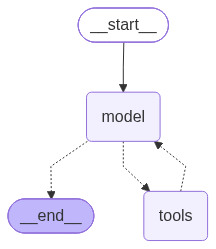

In [15]:
from IPython.display import Image, display


def draw(graph):
    """Draw a LangGraph graph (falls back to text if the drawing service is unreachable)."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


draw(agent)

It is the loop from the slides: `model` → `tools` → back to `model`, until the model stops
calling tools and the run goes to `__end__`. In **notebook B** you will draw your own graphs
with LangGraph, including ones *without* that loop (workflows).

What did LangChain add over your twenty lines? A step limit, tool-error handling, one
interface for many model providers, streaming, and **middleware**: ready-made guardrails such
as tool-call limits and human approval, which you will use in notebook B.

> ⚠️ Most LangChain tutorials online use the pre-1.0 API (`initialize_agent`,
> `AgentExecutor`, `LLMChain`). That API is gone. Look for `create_agent` in the
> [current docs](https://docs.langchain.com/oss/python/langchain/agents).

---
## Wrap-up

* An agent is **an LLM in a loop** with tools. You wrote one in twenty lines.
* **The harness** builds the context, runs the tools and holds the **guardrails**. The model
  only writes requests, so the harness can check, refuse or stop them.
* Guardrails are **code** (allow-lists, limits, checks against the evidence), not polite
  sentences in the prompt.
* **A framework** (LangChain, built on LangGraph) is the same loop with conveniences.

**Next: notebook B**, where the same task is built as an LLM call, a workflow, an agentic
workflow and an agent.

---
## Take-home 1: the same agent, other frameworks

There are many agent frameworks, and they all run the loop from Step 3. Two worth knowing:

* [**Pydantic AI**](https://ai.pydantic.dev) is built around **typed output**: you get a
  validated Python object back, not prose.
* [**DeepAgents**](https://docs.langchain.com/oss/python/deepagents/overview) keeps the same
  loop and adds more harness: a to-do list and a file system for drafts. **Tutorial 2** is
  built on it.

Install them first:

In [16]:
%pip install -q "deepagents==0.7.16" "pydantic-ai==2.46.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.6/328.6 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.9/105.9 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.4/43.4 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 912.2/912.2 kB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.5/142.5 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.8/172.8 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 495.1/49

### Pydantic AI: a literature table, not prose

Prose is a poor deliverable for science: you usually want rows to sort, filter or hand to the
next script. Describe the shape you want as Pydantic classes and pass it as `output_type`.
Same tool, same model, same loop.

Below, each row of the table is a `Paper` with five columns. Each column has a **type** and
a **description**, and both are sent to the model, just like a tool's docstring:

| Column | Type | What the model must put there |
|---|---|---|
| `title`, `link` | text | copied from the search results |
| `method` | text | the method or system studied, in a short phrase |
| `key_finding` | text | one sentence |
| `relevance` | whole number from 1 to 5 | how closely the paper matches **your `TOPIC`**: 1 = only loosely related, 5 = exactly on topic |

`relevance` is the model's own judgment, which helps you sort the table and read the most
relevant papers first.

In [17]:
from typing import List

from pydantic import BaseModel, Field


class Paper(BaseModel):
    title: str = Field(description="Exact title, copied from the search results")
    link: str = Field(description="arXiv link, copied verbatim from the search results")
    method: str = Field(description="The method or system studied, in one short phrase")
    key_finding: str = Field(description="One sentence, in the authors' own terms")
    relevance: int = Field(description="1 = tangential, 5 = directly on topic", ge=1, le=5)


class LiteratureTable(BaseModel):
    """A small literature table built only from real search results."""

    topic: str
    papers: List[Paper]

In [18]:
import pandas as pd
from pydantic_ai import Agent

os.environ["PYDANTIC_AI_NO_BANNER"] = "1"  # hide the start-up banner

pai_agent = Agent(
    PAI_MODEL,
    tools=[search_arxiv],            # the same plain function
    instructions=SYSTEM_PROMPT,
    output_type=LiteratureTable,     # the agent must return this shape
)

# Pydantic AI is async: `await` works at the top level of a Colab cell.
pai_result = await pai_agent.run(f"Build a literature table of 4 recent papers on {TOPIC}.")

print(pai_result.usage)  # requests, tokens: the cost of the run
df = pd.DataFrame([paper.model_dump() for paper in pai_result.output.papers])
df.to_csv("literature_table.csv", index=False)  # now it is just data
df

RunUsage(details={'is_byok': 0, 'audio_tokens': 0, 'reasoning_tokens': 422, 'image_tokens': 0}, input_tokens=5567, output_reasoning_tokens=422, output_tokens=1115, requests=2, tool_calls=2)


,title,link,method,key_finding,relevance
0,Assessing the Transferability of General-Purpo...,http://arxiv.org/abs/2609.30621v1,HetCat26 benchmark of fifteen foundation MLIPs...,Performance on existing general materials benc...,5
1,Quantum-accurate atomistic modeling of enzyme ...,http://arxiv.org/abs/2609.09293v2,Machine-learned interatomic potential eSEN-omo...,The MLIP reproduces experimental barrier trend...,5
2,Mode-Specific Dynamics of $\text{CO}_2$ Hydrog...,http://arxiv.org/abs/2608.27850v2,Full-dimensional neural network potential ener...,The calculations near-quantitatively reproduce...,5
3,Breaking Water at Graphene Defects,http://arxiv.org/abs/2609.11602v1,State-of-the-art machine-learned interatomic p...,Solvation qualitatively changes the reaction m...,4


`pai_result.output` is a Python object, not text that looks like a table, and Pydantic
checked every row before you saw it. That check is a **built-in output guardrail**: if the
model fills `relevance` with something outside the rules above (the text `"very high"`, or
the number `7`), Pydantic rejects the answer and the model is asked to try again.

The check guarantees the *format*, not the *judgment*: a valid `4` is still the model's
opinion of how relevant a paper is, not a measurement. Use it to sort, not to publish.

### DeepAgents: the same loop with a bigger harness

You change one function name. The run takes longer and uses more tokens than Step 5: it
plans, searches several times and writes drafts to its own file system.

In [19]:
from deepagents import create_deep_agent

deep_agent = create_deep_agent(
    model=model,
    tools=[search_arxiv],
    system_prompt=(
        "You are a scientific literature analyst. Plan your work first, then search arXiv "
        "(several focused searches beat one broad one), and write your review to 'review.md' "
        "with the sections: Overview, Methods in use, Open questions, References. "
        "Cite only papers the search tool actually returned, with their links."
    ),
)

result = deep_agent.invoke(
    {"messages": [HumanMessage(f"Write a short review of recent work on {TOPIC}.")]}
)
show_trace(result, width=150)

# DeepAgents keeps its files in the run's state, not on disk.
for path, file in result.get("files", {}).items():
    print(f"\n========== {path} ==========\n{file['content'][:2000]}")

You:         Write a short review of recent work on machine learning interatomic potentials for catalysis.
Thought:     I'll plan this out first, then run several focused searches. **Plan** 1. Search arXiv across distinct sub-topics: (a) MLIPs for [...]
Action:      search_arxiv({'query': 'machine learning interatomic potentials for catalysis', 'max_results': '10'})
Action:      search_arxiv({'query': 'universal machine learning interatomic potential [...]', 'max_results': '10'})
Action:      search_arxiv({'query': 'neural network potential adsorbate metal surface [...]', 'max_results': '10'})
Action:      search_arxiv({'query': 'active learning dataset generation machine learning [...]', 'max_results': '10'})
Observation: 10 papers
Observation: 10 papers
Observation: 0 papers
Observation: 0 papers
Thought:     Two searches were too narrow. Let me run more focused queries.
Action:      search_arxiv({'query': 'machine learning potential heterogeneous catalysis [...]', 'max_results': '10

---
## Take-home 2: exercises

1. **Change the docstring.** Edit the `search_arxiv` docstring (for example, ask for queries
   of at most three words), re-run Step 3, and watch the Actions change.
2. **A second source.** Biology and medicine mostly live on PubMed, not arXiv. Finish
   `search_pubmed` below and give the agent both tools. Watch how it chooses a source, and
   remember that *your docstring* is what teaches it.

In [20]:
# Exercise 2: starter. NCBI E-utilities need no key; keep to 3 requests per second or fewer.
#   search:    {EUTILS}/esearch.fcgi?db=pubmed&retmode=json&term=...&retmax=...
#              -> PubMed IDs, under esearchresult.idlist
#   summarise: {EUTILS}/esummary.fcgi?db=pubmed&retmode=json&id=id1,id2
#              -> titles, journals and dates, under result.<id>
EUTILS = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils"


def search_pubmed(query: str, max_results: int = 5) -> str:
    """TODO: describe this tool for the model: what it searches, and what a good query is.

    Args:
        query: TODO
        max_results: TODO
    """
    raise NotImplementedError


# pubmed_agent = create_agent(model, tools=[search_arxiv, search_pubmed], system_prompt=SYSTEM_PROMPT)

---
*AgentForge Workshop, Tutorial 1A. Questions, fixes and better examples are welcome:
<https://github.com/AgentForgeWorkshop/Tutorials>*